# Recover strain from two Rayleigh traces
Stretch the section from 0.3 to 0.7 m by 1000 microstrain. Use the same seed and optical sweep for the reference and stretched fibre so each contains the same Rayleigh scatterers. The receiver noise is disabled to isolate the strain response.

In [1]:
from copy import deepcopy
import numpy as np
import matplotlib.pyplot as plt

from pyofdr.core.config import load_config
from pyofdr.core.campaign import run_campaign
from pyofdr.analysis.demodulation import reflectogram_from_acq, windowed_xcorr_strain
from pyofdr.utils.constants import C

cfg = load_config('../configs/ofdr_basic.yaml')
cfg['fiber']['length'] = 1.0
cfg['source'].update(linewidth=0, sweep_duration=0.002)
cfg['adc']['sample_rate'] = 100e6
cfg['detection'].update(shot_noise=False, thermal_nep=0, dark_current=0)
cfg['optics']['circulator'].update(isolation_dB=300, return_loss_dB=300)

start, end, imposed = 0.3, 0.7, 1e-3
stretched = deepcopy(cfg)
stretched['strain']['segments'] = [{'start': start, 'end': end, 'epsilon': imposed}]
ref = run_campaign(cfg)[0]
meas = run_campaign(stretched)[0]

## Compare the local spectra
Cross-correlate corresponding 1 cm windows in the two reflectograms. Their optical frequency shift gives $\epsilon=-\Delta\nu/[\nu_0(1-p_e)]$. Use the FFT bin spacing and optical span from the reference acquisition; the windows below cover only the fibre.

In [2]:
H_ref, z = reflectogram_from_acq(ref)
H_meas, _ = reflectogram_from_acq(meas)
on_fiber = z < cfg['fiber']['length']
centres, strain = windowed_xcorr_strain(
    H_meas[on_fiber], H_ref[on_fiber], ref.fft_dz,
    gauge_length=0.01, stride=0.002, sweep_range_hz=ref.fft_sweep_range_hz,
    center_freq=C / cfg['source']['center_wavelength'],
    p_e=cfg['strain']['photoelastic_coefficient'],
)

# Boundary windows mix strained and unstrained scatterers.
inside = (centres > start + 0.05) & (centres < end - 0.05)
quiet = (centres > 0.05) & (centres < start - 0.05)
recovered = np.median(strain[inside])
print(f"Imposed {1e6 * imposed:.1f} µε, recovered {1e6 * recovered:.1f} µε")
print(f"Relative error {100 * (recovered / imposed - 1):.2f}%")
print(f"Median in the unstrained region: {1e6 * np.median(strain[quiet]):.2f} µε")

Imposed 1000.0 µε, recovered 1000.1 µε
Relative error 0.01%
Median in the unstrained region: -0.02 µε


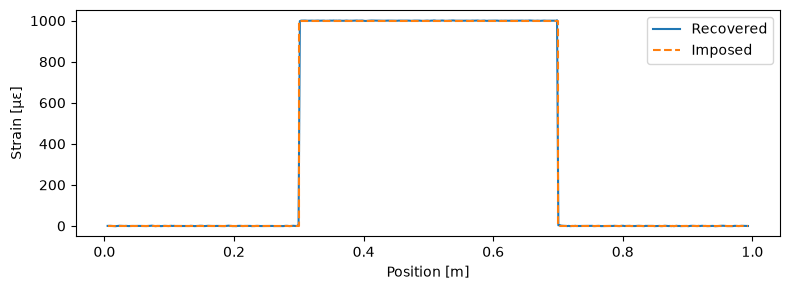

In [3]:
ground_truth = np.where((centres >= start) & (centres < end), imposed, 0)
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(centres, strain * 1e6, label='Recovered')
ax.step(centres, ground_truth * 1e6, where='mid', label='Imposed', linestyle='--')
ax.set(xlabel='Position [m]', ylabel='Strain [µε]')
ax.legend()
fig.tight_layout()
plt.show()